# Housing Data Analysis and Visualization

## Minor Project

### Objective
To explore and visualize housing data using Python, Pandas, NumPy, Matplotlib, and Seaborn.

### Dataset
The dataset contains information about 545 houses and 13 attributes including price, area, bedrooms, bathrooms, stories, parking, air conditioning, and preferred area.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("Housing.csv")

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape:
(545, 13)

Column Names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingst

In [5]:
df.describe()


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


## Question 1: House Price Range Analysis

### Objective

To find the number of houses in the following price ranges:

- 0–25 Lakhs
- 26–50 Lakhs
- 51–75 Lakhs
- 76–100 Lakhs
- Above 100 Lakhs

The results are visualized using a line chart.

In [6]:
df['price_lakh'] = df['price'] / 100000

df[['price', 'price_lakh']].head()

,price,price_lakh
0,13300000,133.00
1,12250000,122.50
2,12250000,122.50
3,12215000,122.15
4,11410000,114.10


In [7]:
bins = [0, 25, 50, 75, 100, np.inf]

labels = [
    '0-25 Lakhs',
    '26-50 Lakhs',
    '51-75 Lakhs',
    '76-100 Lakhs',
    '>100 Lakhs'
]

df['price_range'] = pd.cut(
    df['price_lakh'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

df[['price_lakh', 'price_range']].head(10)

,price_lakh,price_range
0,133.00,>100 Lakhs
1,122.50,>100 Lakhs
2,122.50,>100 Lakhs
3,122.15,>100 Lakhs
4,114.10,>100 Lakhs
5,108.50,>100 Lakhs
6,101.50,>100 Lakhs
7,101.50,>100 Lakhs
8,98.70,76-100 Lakhs
9,98.00,76-100 Lakhs


In [8]:
price_counts = df['price_range'].value_counts().reindex(labels)

print(price_counts)


price_range
0-25 Lakhs       32
26-50 Lakhs     318
51-75 Lakhs     148
76-100 Lakhs     39
>100 Lakhs        8
Name: count, dtype: int64


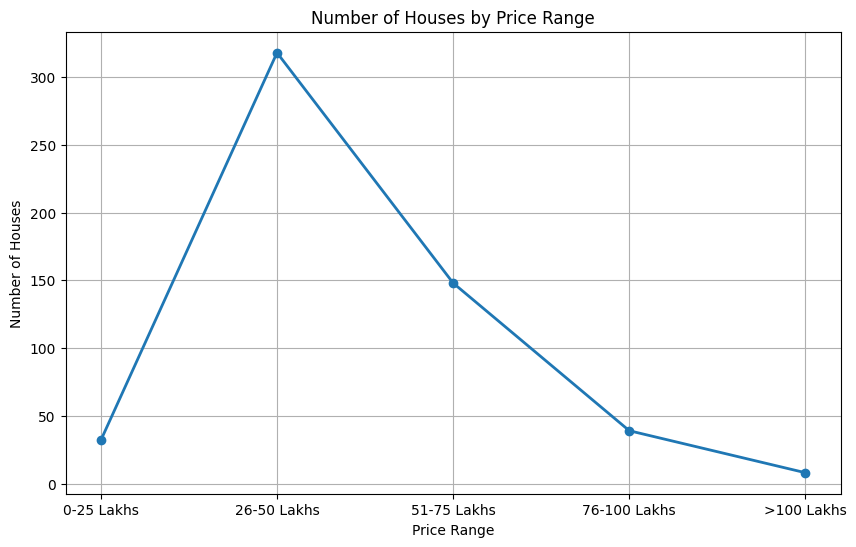

In [9]:
plt.figure(figsize=(10, 6))

plt.plot(
    price_counts.index,
    price_counts.values,
    marker='o',
    linewidth=2
)

plt.title('Number of Houses by Price Range')
plt.xlabel('Price Range')
plt.ylabel('Number of Houses')
plt.grid(True)

plt.show()

## Question 2: Average Price of AC and Non-AC Houses

### Objective

To calculate and compare the average prices of houses with air conditioning and houses without air conditioning.

The comparison is visualized using a bar chart.

In [10]:
df['airconditioning'].value_counts()


,count
airconditioning,
no,373
yes,172


In [11]:
ac_average = df.groupby('airconditioning')['price'].mean()

print(ac_average)

airconditioning
no     4.191940e+06
yes    6.013221e+06
Name: price, dtype: float64


In [12]:
ac_average_lakh = ac_average / 100000

print(ac_average_lakh)

airconditioning
no     41.919397
yes    60.132206
Name: price, dtype: float64


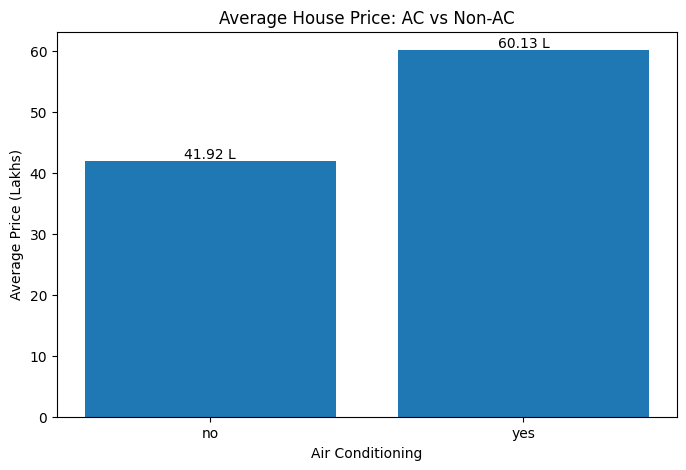

In [13]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ac_average_lakh.index,
    ac_average_lakh.values
)

plt.title('Average House Price: AC vs Non-AC')
plt.xlabel('Air Conditioning')
plt.ylabel('Average Price (Lakhs)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.2f} L',
        ha='center',
        va='bottom'
    )

plt.show()

## Question 3: Relationship Between Parking and House Price

### Objective

To analyze the relationship between the number of parking spaces and house prices using statistical analysis and visualization.

The relationship is first visualized using a scatter plot and then summarized using average house prices for each parking category.

In [14]:
parking_analysis = df.groupby('parking')['price'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

parking_analysis

,count,mean,median,min,max
parking,,,,,
0,299,4.136017e+06,3850000.0,1750000,10150000
1,126,5.190389e+06,4690000.0,1855000,9800000
2,108,5.896328e+06,5302500.0,1820000,13300000
3,12,5.867167e+06,4375000.0,3010000,12250000


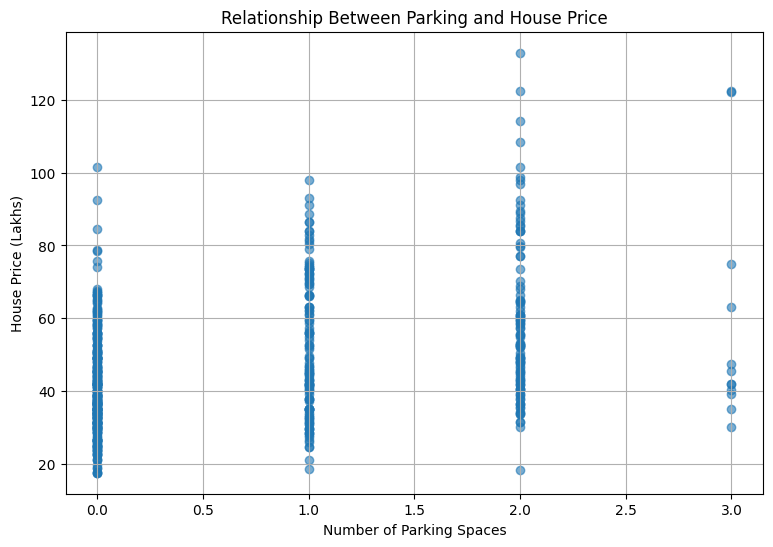

In [15]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df['parking'],
    df['price'] / 100000,
    alpha=0.6
)

plt.title('Relationship Between Parking and House Price')
plt.xlabel('Number of Parking Spaces')
plt.ylabel('House Price (Lakhs)')
plt.grid(True)

plt.show()

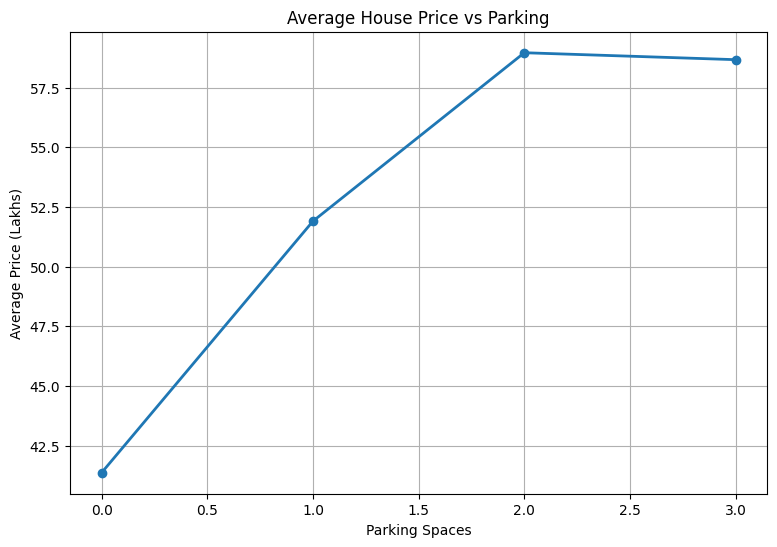

In [16]:
parking_avg = df.groupby('parking')['price'].mean() / 100000

plt.figure(figsize=(9, 6))

plt.plot(
    parking_avg.index,
    parking_avg.values,
    marker='o',
    linewidth=2
)

plt.title('Average House Price vs Parking')
plt.xlabel('Parking Spaces')
plt.ylabel('Average Price (Lakhs)')
plt.grid(True)

plt.show()

## Question 4: Price Gap Based on Area and Preferred Area

### Objective

To compare the average prices of houses having area below 5000 sqft with no preferred area and houses having area above 5000 sqft with a preferred area.

The price difference between these two groups is calculated and visualized using a bar chart.

In [17]:
group1 = df[
    (df['area'] < 5000) &
    (df['prefarea'] == 'no')
]

group2 = df[
    (df['area'] > 5000) &
    (df['prefarea'] == 'yes')
]

print("Group 1 houses:", len(group1))
print("Group 2 houses:", len(group2))

Group 1 houses: 269
Group 2 houses: 91


In [18]:
group1_avg = group1['price'].mean()
group2_avg = group2['price'].mean()

print("Group 1 Average Price:",
      group1_avg / 100000, "Lakhs")

print("Group 2 Average Price:",
      group2_avg / 100000, "Lakhs")

price_gap = abs(group2_avg - group1_avg)

print("Price Gap:",
      price_gap / 100000, "Lakhs")

Group 1 Average Price: 38.2767156133829 Lakhs
Group 2 Average Price: 65.46807692307692 Lakhs
Price Gap: 27.19136130969402 Lakhs


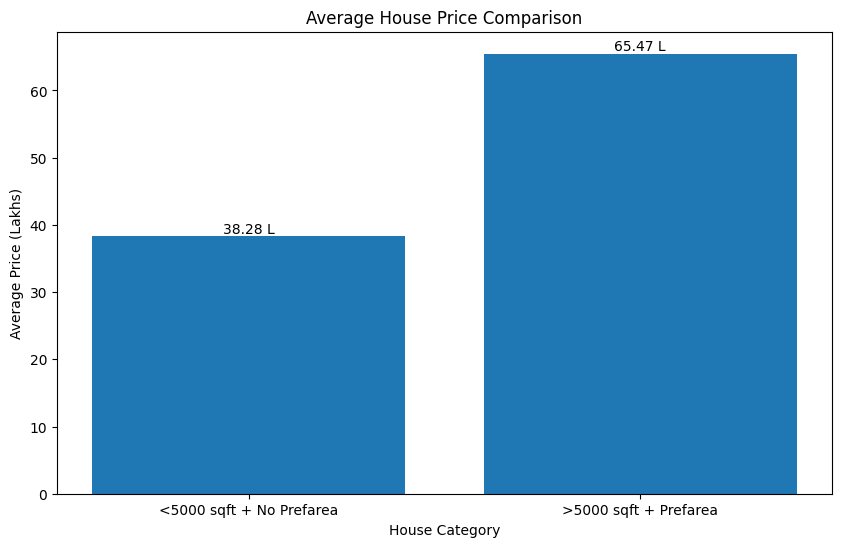

In [19]:
groups = [
    '<5000 sqft + No Prefarea',
    '>5000 sqft + Prefarea'
]

averages = [
    group1_avg / 100000,
    group2_avg / 100000
]

plt.figure(figsize=(10, 6))

bars = plt.bar(groups, averages)

plt.title('Average House Price Comparison')
plt.xlabel('House Category')
plt.ylabel('Average Price (Lakhs)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.2f} L',
        ha='center',
        va='bottom'
    )

plt.show()

## Conclusion

This project analyzed 545 houses using Python, Pandas, NumPy, Matplotlib, and Seaborn.

### Key Findings

- The 26–50 lakhs price range contains the highest number of houses, with 318 houses.
- Houses with air conditioning have an average price of approximately ₹60.13 lakhs, compared with ₹41.92 lakhs for houses without air conditioning.
- Average house prices vary across different parking categories, ranging from approximately ₹41.36 lakhs for no parking to ₹58.96 lakhs for two parking spaces.
- Houses with area above 5000 sqft and a preferred area have an average price of approximately ₹65.47 lakhs.
- Houses with area below 5000 sqft and no preferred area have an average price of approximately ₹38.28 lakhs.
- The calculated price gap between the two groups is approximately ₹27.19 lakhs.

### Conclusion

The analysis demonstrates how exploratory data analysis and visualization can be used to understand patterns in housing prices and the relationship between house features and price.